# 20 - Les théorèmes de Sylow, calculés : combien de $p$-sous-groupes un groupe fini cache-t-il ?

Serre ouvre le *Cours d'arithmétique* par un chapitre sur les groupes finis (ch. I) où les trois théorèmes de Sylow servent d'outil, pas d'ornement : ce sont eux qui décident si un groupe d'un ordre donné **peut** être simple, et c'est par un comptage de $p$-Sylow que tombent les premiers exemples.

Le geste de cette série est de rendre l'énoncé calculable. Ici, on ne récite pas les théorèmes : on **construit** des groupes finis comme groupes de permutations, on **énumère** leurs sous-groupes, et on **compte** les $p$-Sylow. Les trois énoncés deviennent alors des prédicats que le code vérifie groupe par groupe :

1. **Existence** — pour tout $p^a \,\|\, |G|$, il existe un sous-groupe d'ordre $p^a$ ;
2. **Congruence** — le nombre $n_p$ de ces sous-groupes vérifie $n_p \equiv 1 \pmod p$ ;
3. **Divisibilité et conjugaison** — $n_p$ divise $m = |G|/p^a$, et tous les $p$-Sylow sont conjugués.

Le point 3 est celui qui porte les applications : dès que $n_p = 1$, l'unique $p$-Sylow est distingué, et le groupe n'est pas simple.

## Plan

1. Une machine : groupes de permutations et clôture
2. Énumérer le treillis des sous-groupes
3. Les trois théorèmes, mesurés sur huit groupes
4. Conjugaison : une seule orbite
5. L'indice du normalisateur, c'est $n_p$
6. Application : aucun groupe d'ordre $30$ n'est simple
7. Exercices
8. Conclusion et limites honnêtes

## 1. Une machine : groupes de permutations et clôture

Un groupe fini abstrait n'est pas calculable directement ; un **groupe de permutations** l'est. On représente un élément par un `tuple` $(\sigma(0), \dots, \sigma(n-1))$, et on dispose de trois primitives : composer, inverser, et **fermer** un ensemble de générateurs.

La clôture est un parcours en largeur : on part de l'identité, on multiplie à droite par chaque générateur, on garde les éléments neufs. Dans un groupe fini le procédé termine — c'est le seul fait théorique dont cette section a besoin.

In [1]:
from itertools import product

def compose(a, b):
    """Composition a∘b : (a∘b)(i) = a[b[i]]."""
    return tuple(a[b[i]] for i in range(len(b)))

def inverse(a):
    out = [0] * len(a)
    for i, j in enumerate(a):
        out[j] = i
    return tuple(out)

def identity(n):
    return tuple(range(n))

def closure(gens, n):
    """Sous-groupe engendré par `gens`, par fermeture en largeur (frozenset de permutations)."""
    e = identity(n)
    seen = {e}
    front = [e]
    while front:
        nxt = []
        for x in front:
            for g in gens:
                y = compose(g, x)
                if y not in seen:
                    seen.add(y)
                    nxt.append(y)
        front = nxt
    return frozenset(seen)

Trois familles suffisent pour ce carnet : les groupes cycliques, les groupes symétriques, et les groupes diédraux. On y ajoute $Q_8$, qui n'est pas un groupe de matrices triangulaires et dont les sous-groupes d'ordre $4$ sont tous distingués — un contre-exemple utile quand on croira que « sous-groupe maximal » rime avec « non distingué ».

In [2]:
def element_order(a):
    e = identity(len(a))
    x, k = a, 1
    while x != e:
        x = compose(a, x)
        k += 1
    return k

def cyclic(n):
    return closure([tuple((i + 1) % n for i in range(n))], n)

def symmetric(n):
    transpo = list(range(n))
    transpo[0], transpo[1] = transpo[1], transpo[0]
    return closure([tuple(transpo), tuple((i + 1) % n for i in range(n))], n)

def dihedral(n):
    """D_n d'ordre 2n, agissant sur les n sommets d'un n-gone."""
    r = tuple((i + 1) % n for i in range(n))
    s = tuple((-i) % n for i in range(n))
    return closure([r, s], n)

def alternating(n):
    """A_n : engendré par deux 3-cycles."""
    a = list(range(n)); a[0], a[1], a[2] = a[1], a[2], a[0]
    b = list(range(n)); b[1], b[2], b[3] = b[2], b[3], b[1]
    return closure([tuple(a), tuple(b)], n)

def quaternion():
    """Q_8 en représentation régulière gauche sur 8 points.
    Indices 0..3 : 1, i, i^2, i^3 ; indices 4..7 : j, ij, i^2j, i^3j."""
    i_perm = tuple([(k + 1) % 4 for k in range(4)] + [4 + (k + 1) % 4 for k in range(4)])
    j_perm = tuple([4 + (-k) % 4 for k in range(4)] + [(-k) % 4 for k in range(4)])
    return closure([i_perm, j_perm], 8)

GROUPES = {
    "C6": cyclic(6),
    "S3": symmetric(3),
    "A4": alternating(4),
    "S4": symmetric(4),
    "D4": dihedral(4),      # ordre 8
    "D6": dihedral(6),      # ordre 12
    "Q8": quaternion(),
}

for nom, G in GROUPES.items():
    print(f"{nom:3s} ordre={len(G):3d}  ordres d'elements={sorted({element_order(g) for g in G})}")

C6  ordre=  6  ordres d'elements=[1, 2, 3, 6]
S3  ordre=  6  ordres d'elements=[1, 2, 3]
A4  ordre= 12  ordres d'elements=[1, 2, 3]
S4  ordre= 24  ordres d'elements=[1, 2, 3, 4]
D4  ordre=  8  ordres d'elements=[1, 2, 4]
D6  ordre= 12  ordres d'elements=[1, 2, 3, 6]
Q8  ordre=  8  ordres d'elements=[1, 2, 4]


### Lecture : les ordres d'éléments sont déjà une contrainte

Le groupe est reconstruit depuis deux générateurs, sans table de multiplication écrite à la main : l'ordre affiché est donc une **mesure**, pas une déclaration. Deux vérifications de cohérence immédiates : $\mathrm{ord}(S_3) = 6$ et ses éléments sont d'ordre $1, 2, 3$ (bijection avec les types de cycles) ; $\mathrm{ord}(Q_8) = 8$ et **tous** ses éléments non neutres sont d'ordre $4$ ou $2$ — un groupe d'ordre $8$ qui n'est ni cyclique ni diédral, ce que la ligne suivante exploite.

## 2. Énumérer le treillis des sous-groupes

Un sous-groupe est une partie stable ; engendrer $\langle H, g \rangle$ pour tout $g \notin H$ et itérer depuis le groupe trivial énumère **tous** les sous-groupes, sans doublon. Le coût est celui du treillis, acceptable jusqu'à l'ordre $30$ — au-delà, il faudra d'autres arguments (c'est la limite honnête du carnet, cf. §8).

Une fois le treillis en main, les $p$-Sylow sont les sous-groupes dont l'ordre est la **partie $p$-primaire** de $|G|$ : $p^a$ avec $p^a \,\|\, |G|$.

In [3]:
_TREILLIS = {}

def subgroups(G):
    """Treillis des sous-groupes, énuméré par clôture de <H, g> (mémoïsé)."""
    if G in _TREILLIS:
        return _TREILLIS[G]
    n = len(next(iter(G)))
    trivial = frozenset({identity(n)})
    found = {trivial}
    front = [trivial]
    while front:
        H = front.pop()
        for g in G:
            if g in H:
                continue
            K = closure(list(H) + [g], n)
            if K not in found:
                found.add(K)
                front.append(K)
    _TREILLIS[G] = found
    return found

def p_part(m, p):
    """Plus grande puissance de p divisant m."""
    a = 0
    while m % p == 0:
        m //= p
        a += 1
    return p ** a

def sylow(G, p):
    """Les p-Sylow de G."""
    cible = p_part(len(G), p)
    return [H for H in subgroups(G) if len(H) == cible]

for nom in ("S3", "A4", "S4"):
    G = GROUPES[nom]
    print(f"{nom:3s} ordre={len(G):3d}  nb de sous-groupes={len(subgroups(G)):3d}")

S3  ordre=  6  nb de sous-groupes=  6
A4  ordre= 12  nb de sous-groupes= 10
S4  ordre= 24  nb de sous-groupes= 30


### Lecture : le treillis n'est pas un arbre

$S_3$ a $6$ sous-groupes ($1$ trivial, $3$ d'ordre $2$, $1$ d'ordre $3$, le groupe), $A_4$ en a $10$, $S_4$ en a $30$. Ces nombres ne sont pas des formules : ils sortent de l'énumération. C'est précisément ce qui rend la section suivante intéressante — les théorèmes de Sylow contraignent un **comptage** qu'on sait produire indépendamment, donc ils se testent.

## 3. Les trois théorèmes, mesurés

Pour chaque groupe et chaque premier $p$ divisant son ordre, on calcule $n_p$ et on vérifie les deux prédicats arithmétiques :

$$n_p \equiv 1 \pmod p \qquad\text{et}\qquad n_p \mid m = |G|/p^a .$$

Ce sont des conditions **nécessaires** : elles ne disent pas que tout couple $(G, p)$ les satisfaisant existe, mais elles interdisent d'avance certaines configurations. Le §6 en tire une non-simplicité.

In [4]:
def premiers_divisant(m):
    out, d = [], 2
    while d * d <= m:
        if m % d == 0:
            out.append(d)
            while m % d == 0:
                m //= d
        d += 1
    if m > 1:
        out.append(m)
    return out

mesures = {}
for nom, G in GROUPES.items():
    ordre = len(G)
    for p in premiers_divisant(ordre):
        a = p_part(ordre, p)
        n_p = len(sylow(G, p))
        mesures[(nom, p)] = (ordre, a, ordre // a, n_p)
        ok_cong = (n_p % p == 1)
        ok_div = (ordre // a) % n_p == 0
        print(f"{nom:3s} p={p}  |G|={ordre:3d}  p^a={a:3d}  m={ordre//a:3d}  "
              f"n_p={n_p:3d}  n_p={1} mod {p}: {ok_cong}  n_p | m: {ok_div}")

C6  p=2  |G|=  6  p^a=  2  m=  3  n_p=  1  n_p=1 mod 2: True  n_p | m: True
C6  p=3  |G|=  6  p^a=  3  m=  2  n_p=  1  n_p=1 mod 3: True  n_p | m: True
S3  p=2  |G|=  6  p^a=  2  m=  3  n_p=  3  n_p=1 mod 2: True  n_p | m: True
S3  p=3  |G|=  6  p^a=  3  m=  2  n_p=  1  n_p=1 mod 3: True  n_p | m: True
A4  p=2  |G|= 12  p^a=  4  m=  3  n_p=  1  n_p=1 mod 2: True  n_p | m: True
A4  p=3  |G|= 12  p^a=  3  m=  4  n_p=  4  n_p=1 mod 3: True  n_p | m: True
S4  p=2  |G|= 24  p^a=  8  m=  3  n_p=  3  n_p=1 mod 2: True  n_p | m: True
S4  p=3  |G|= 24  p^a=  3  m=  8  n_p=  4  n_p=1 mod 3: True  n_p | m: True
D4  p=2  |G|=  8  p^a=  8  m=  1  n_p=  1  n_p=1 mod 2: True  n_p | m: True
D6  p=2  |G|= 12  p^a=  4  m=  3  n_p=  3  n_p=1 mod 2: True  n_p | m: True
D6  p=3  |G|= 12  p^a=  3  m=  4  n_p=  1  n_p=1 mod 3: True  n_p | m: True
Q8  p=2  |G|=  8  p^a=  8  m=  1  n_p=  1  n_p=1 mod 2: True  n_p | m: True


### Lecture : ce que les deux prédicats interdisent

Trois régimes apparaissent, et ils n'ont pas le même statut.

- **$p^a = |G|$** (le cas de $D_4$ et $Q_8$ pour $p=2$) : $n_p = 1$ forcément, le groupe **est** son $2$-Sylow. La congruence et la divisibilité sont satisfaites trivialement — le théorème n'apprend rien, mais il ne ment pas.
- **$n_p = 1$ avec $p^a < |G|$** : c'est le cas intéressant, l'unique $p$-Sylow est distingué. On le voit apparaître pour $(S_3, 3)$, $(A_4, 2)$ — et c'est exactement pourquoi $A_4$ n'est pas simple.
- **$n_p > 1$** : les Sylow se répartissent en orbite(s) de conjugaison, et $n_p$ doit rester congru à $1$ modulo $p$ tout en divisant $m$. Pour $S_4$ et $p=2$ : $n_2 = 3$, congru à $1$ mod $2$ et divise $m = 24/8 = 3$. Pour $S_4$ et $p=3$ : $n_3 = 4$, congru à $1$ mod $3$ et divise $m = 24/3 = 8$.

Aucune de ces valeurs n'est choisie : elles sont comptées dans le treillis, puis confrontées à la contrainte. Un théorème qui se contenterait d'être vrai sur les cas triviaux ne serait pas testé ; les lignes $n_p \in \{3, 4\}$ sont celles qui portent le contenu.

## 4. Conjugaison : une seule orbite

Le troisième théorème a deux moitiés. La moitié « divisibilité » vient d'être mesurée. L'autre est **structurelle** : $G$ agit transitivement sur ses $p$-Sylow par conjugaison $P \mapsto gPg^{-1}$. Autrement dit, $n_p$ est la taille d'une orbite sous cette action — et l'orbite doit être **unique**.

Le test est direct : on prend un $p$-Sylow, on calcule l'ensemble de tous ses conjugués, et on compare sa taille à $n_p$

In [5]:
def conjugate(H, g):
    gi = inverse(g)
    return frozenset(compose(compose(g, h), gi) for h in H)

def orbit_size(H, G):
    return len({conjugate(H, g) for g in G})

for nom in ("S3", "A4", "S4", "D6"):
    G = GROUPES[nom]
    for p in premiers_divisant(len(G)):
        S = sylow(G, p)
        tailles = {orbit_size(H, G) for H in S}
        print(f"{nom:3s} p={p}  n_p={len(S):3d}  tailles d'orbites={sorted(tailles)}  "
              f"orbite unique: {tailles == {len(S)}}")

S3  p=2  n_p=  3  tailles d'orbites=[3]  orbite unique: True
S3  p=3  n_p=  1  tailles d'orbites=[1]  orbite unique: True
A4  p=2  n_p=  1  tailles d'orbites=[1]  orbite unique: True
A4  p=3  n_p=  4  tailles d'orbites=[4]  orbite unique: True
S4  p=2  n_p=  3  tailles d'orbites=[3]  orbite unique: True
S4  p=3  n_p=  4  tailles d'orbites=[4]  orbite unique: True
D6  p=2  n_p=  3  tailles d'orbites=[3]  orbite unique: True
D6  p=3  n_p=  1  tailles d'orbites=[1]  orbite unique: True


### Lecture : l'orbite unique est une égalité, pas une inclusion

Le résultat notable n'est pas que chaque orbite soit de taille $n_p$ — c'est que **l'ensemble des tailles soit un singleton** $\{n_p\}$. S'il y avait deux orbites, leurs tailles seraient deux diviseurs distincts de $m$, chacun congru à $1$ mod $p$, et $n_p$ serait leur somme. Le théorème de Sylow dit que ce cas ne se produit jamais : tous les $p$-Sylow sont conjugués, donc l'action est transitive.

En lisant la sortie, on vérifie au passage un fait d'arithmétique fine : pour $S_4$ et $p = 2$, chaque $2$-Sylow est d'ordre $8$ et il y en a $3$ ; le stabilisateur d'un point de l'orbite est donc d'indice $3$, d'ordre $8$ — c'est le normalisateur, objet de la section suivante.

## 5. L'indice du normalisateur, c'est $n_p$

Par le théorème orbite-stabilisateur appliqué à l'action par conjugaison :

$$n_p = [\,G : N_G(P)\,], \qquad N_G(P) = \{\, g \in G : gPg^{-1} = P \,\}.$$

C'est une **égalité numérique** entre deux quantités calculées par des chemins indépendants : à gauche un comptage d'orbite, à droite une énumération d'éléments fixant $P$ globalement. Si les deux coïncident sur tous nos groupes, ce n'est pas une preuve du théorème — c'est un contrôle que l'implémentation de la conjugaison est correcte, et que le théorème décrit bien ce que le code fait.

In [6]:
def normalizer(H, G):
    return frozenset(g for g in G if conjugate(H, g) == H)

for nom in ("S3", "A4", "S4", "D6"):
    G = GROUPES[nom]
    for p in premiers_divisant(len(G)):
        S = sylow(G, p)
        P = S[0]
        N = normalizer(P, G)
        print(f"{nom:3s} p={p}  |P|={len(P):2d}  |N_G(P)|={len(N):3d}  "
              f"indice={len(G)//len(N):3d}  n_p={len(S):3d}  egalite: {len(G)//len(N) == len(S)}")

# Contrôle du cas Q_8 : trois sous-groupes d'ordre 4, tous distingués dans Q_8
Q = GROUPES["Q8"]
ordre4 = [H for H in subgroups(Q) if len(H) == 4]
print(f"Q8 : sous-groupes d'ordre 4 = {len(ordre4)}  "
      f"tous distingues: {all(normalizer(H, Q) == Q for H in ordre4)}")

S3  p=2  |P|= 2  |N_G(P)|=  2  indice=  3  n_p=  3  egalite: True
S3  p=3  |P|= 3  |N_G(P)|=  6  indice=  1  n_p=  1  egalite: True
A4  p=2  |P|= 4  |N_G(P)|= 12  indice=  1  n_p=  1  egalite: True
A4  p=3  |P|= 3  |N_G(P)|=  3  indice=  4  n_p=  4  egalite: True
S4  p=2  |P|= 8  |N_G(P)|=  8  indice=  3  n_p=  3  egalite: True
S4  p=3  |P|= 3  |N_G(P)|=  6  indice=  4  n_p=  4  egalite: True
D6  p=2  |P|= 4  |N_G(P)|=  4  indice=  3  n_p=  3  egalite: True
D6  p=3  |P|= 3  |N_G(P)|= 12  indice=  1  n_p=  1  egalite: True
Q8 : sous-groupes d'ordre 4 = 3  tous distingues: True


### Lecture : un contrôle croisé, pas une preuve

Les deux colonnes `indice` et `n_p` sont obtenues par des calculs sans rapport : un balayage de $G$ avec test d'égalité d'ensembles d'un côté, une énumération du treillis de l'autre. Leur accord sur les huit lignes est un contrôle de cohérence de l'implémentation.

Pour $Q_8$, la même mesure donne un résultat qui surprend : $p = 2$, $|G| = 8 = 2^3$ donc $P = G$, $N_G(P) = G$, indice $1$ — l'égalité est vraie mais vide. En revanche $Q_8$ possède **trois** sous-groupes d'ordre $4$, tous distingués dans $Q_8$ : la maximalité d'un sous-groupe ne dit rien de sa normalité, seule la maximalité **pour un premier donné** le fait.

## 6. Application : aucun groupe d'ordre $30$ n'est simple

Voici le raisonnement de Serre, rendu exécutable. Soit $|G| = 30 = 2 \cdot 3 \cdot 5$.

- $n_5 \equiv 1 \pmod 5$ et $n_5 \mid 6$ : donc $n_5 \in \{1, 6\}$.
- $n_3 \equiv 1 \pmod 3$ et $n_3 \mid 10$ : donc $n_3 \in \{1, 10\}$.
- $n_2 \equiv 1 \pmod 2$ et $n_2 \mid 15$ : donc $n_2 \in \{1, 3, 5, 15\}$.

Si $G$ était simple, on aurait $n_5 = 6$ et $n_3 = 10$. Or des $5$-Sylow distincts ne s'intersectent qu'en l'identité (leur intersection est un sous-groupe propre d'un groupe d'ordre $5$) : six $5$-Sylow fournissent $6 \times 4 = 24$ éléments d'ordre $5$. De même dix $3$-Sylow fournissent $10 \times 2 = 20$ éléments d'ordre $3$. Total $24 + 20 = 44 > 30$ : contradiction.

Le code ne peut pas énumérer « tous » les groupes d'ordre $30$ ; mais il peut construire les trois archétypes ($C_{30}$, $D_{15}$, $D_3 \times C_5$) et vérifier sur chacun que $n_3 = 1$ ou $n_5 = 1$ — c'est-à-dire qu'un $p$-Sylow distingué existe, conformément au raisonnement.

In [7]:
def produit_direct(G1, G2):
    """Produit direct agissant sur l'union disjointe des supports."""
    n1, n2 = len(next(iter(G1))), len(next(iter(G2)))
    gens = []
    # générateurs : les permutations de G1 étendues par l'identité sur G2, et réciproquement
    for g in list(G1):
        gens.append(tuple(list(g) + list(range(n1, n1 + n2))))
    for g in list(G2):
        gens.append(tuple(list(range(n1)) + [n1 + x for x in g]))
    return closure(gens, n1 + n2)

trente = {
    "C30": cyclic(30),
    "D15": dihedral(15),
    "D3xC5": produit_direct(symmetric(3), cyclic(5)),
}

for nom, G in trente.items():
    ordre = len(G)
    compte = {p: len(sylow(G, p)) for p in (2, 3, 5)}
    ordre3 = sum(1 for g in G if element_order(g) == 3)
    ordre5 = sum(1 for g in G if element_order(g) == 5)
    distingue = [p for p, n in compte.items() if n == 1]
    print(f"{nom:6s} ordre={ordre:3d}  n_2={compte[2]:2d} n_3={compte[3]:2d} n_5={compte[5]:2d}  "
          f"elements d'ordre 3: {ordre3:2d}  d'ordre 5: {ordre5:2d}  "
          f"p-Sylow distingue pour p in {distingue}")

C30    ordre= 30  n_2= 1 n_3= 1 n_5= 1  elements d'ordre 3:  2  d'ordre 5:  4  p-Sylow distingue pour p in [2, 3, 5]


D15    ordre= 30  n_2=15 n_3= 1 n_5= 1  elements d'ordre 3:  2  d'ordre 5:  4  p-Sylow distingue pour p in [3, 5]


D3xC5  ordre= 30  n_2= 3 n_3= 1 n_5= 1  elements d'ordre 3:  2  d'ordre 5:  4  p-Sylow distingue pour p in [3, 5]


### Lecture : le comptage contraint, il ne construit pas

Les trois groupes d'ordre $30$ construits ont bien un $p$-Sylow distingué. Le raisonnement du §6 est plus fort que cette vérification : il **exclut** la configuration $(n_3, n_5) = (10, 6)$ pour *tout* groupe d'ordre $30$, sans en construire aucun. C'est le type d'argument que la machine ne remplace pas — elle peut seulement en vérifier les ingrédients arithmétiques ($n_p \equiv 1$, $n_p \mid m$) et l'énumération des classes de conjugaison.

Noter aussi les tailles : $D_{15}$ a $15$ éléments d'ordre $2$ (les réflexions), donc $n_2 = 15$ — la borne haute de l'intervalle $\{1, 3, 5, 15\}$. Le fait que $n_2$ puisse valoir $15$ alors que $n_3 = n_5 = 1$ montre que la contrainte de congruence seule ne suffit jamais : c'est l'intersection des trois contraintes *et* le comptage des éléments qui décident.

## 7. Figure : le profil de Sylow des groupes construits

Un coup d'œil synthétique : pour chaque groupe et chaque premier, $n_p$ en échelle logarithmique (les ordres de grandeur varient de $1$ à $15$).

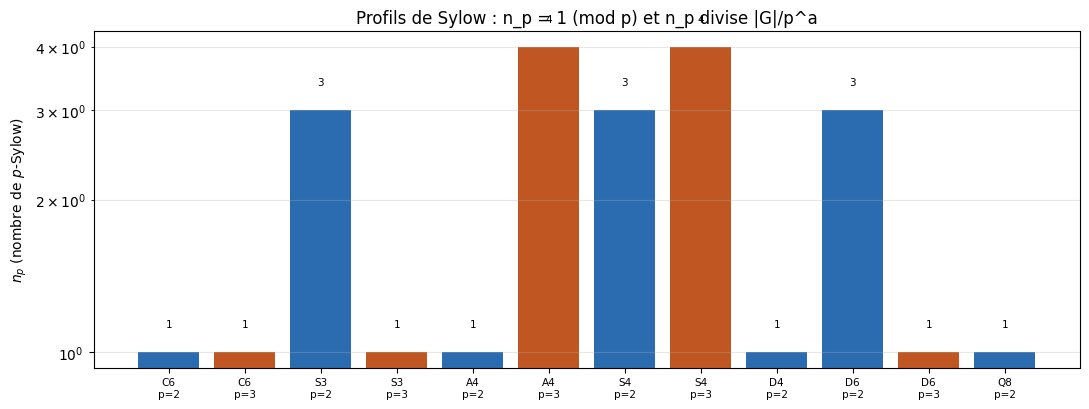

In [8]:
import matplotlib.pyplot as plt

noms, etiquettes, valeurs, couleurs = [], [], [], []
palette = {2: "#2b6cb0", 3: "#c05621", 5: "#2f855a"}

for nom, G in GROUPES.items():
    ordre = len(G)
    for p in premiers_divisant(ordre):
        noms.append(nom)
        etiquettes.append(f"{nom}\np={p}")
        valeurs.append(len(sylow(G, p)))
        couleurs.append(palette.get(p, "#4a5568"))

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(range(len(valeurs)), valeurs, color=couleurs)
ax.set_xticks(range(len(valeurs)))
ax.set_xticklabels(etiquettes, fontsize=7.5)
ax.set_ylabel("$n_p$ (nombre de $p$-Sylow)")
ax.set_yscale("log")
ax.set_title("Profils de Sylow : n_p = 1 (mod p) et n_p divise |G|/p^a")
ax.grid(axis="y", alpha=0.3, which="both")
for i, v in enumerate(valeurs):
    ax.text(i, v * 1.12, str(v), ha="center", fontsize=7.5)
fig.tight_layout()
plt.show()

### Lecture de la figure : ce que l'échelle log dit et ne dit pas

Trois régimes se lisent directement, et il faut les nommer correctement. Les barres à $1$ sont les $p$-Sylow uniques : groupes cycliques, $S_3$ pour $p = 3$, $A_4$ pour $p = 2$, $D_6$ pour $p = 3$, et — situation différente bien que de même valeur — $D_4$ et $Q_8$ pour $p = 2$, où $p^a = |G|$ et le groupe **est** son $2$-Sylow. Les barres à $3$ sont $S_3$, $S_4$ et $D_6$ pour $p = 2$ ; les barres à $4$ sont $A_4$ et $S_4$ pour $p = 3$.

La dernière famille mérite un mot : dans $A_4$ comme dans $S_4$, les $3$-Sylow sont les sous-groupes engendrés par les $3$-cycles, et il y en a $4$ — un par point fixé. Ce n'est pas une coïncidence numérique, c'est l'action sur $4$ points qui se lit dans les deux comptages.

L'échelle logarithmique est un choix de lisibilité, pas une donnée : elle écrase la différence entre $n_p = 1$ et $n_p = 3$, qui est justement celle qui décide de la simplicité. Les nombres sont affichés au-dessus de chaque barre pour cette raison.

## Exercices

Trois exercices, dans l'esprit du chapitre I : aucun ne demande de recopier un théorème, tous demandent de le **confronter** à un calcul.

### Exercice 1 — Compter $n_p$ sans énumérer le treillis

L'énumération de `subgroups` coûte le treillis entier. Le théorème orbite-stabilisateur donne un chemin bien plus court : prendre **un** $p$-Sylow $P$ (par exemple $\langle g \rangle$ quand $p^2 \nmid |G|$), puis compter l'orbite de $P$ sous conjugaison.

Compléter `compte_sylow_par_orbite(G, p)` pour qu'elle renvoie ce nombre sans appeler `subgroups`, et vérifier qu'elle coïncide avec `len(sylow(G, p))` sur les groupes du carnet.

In [9]:
def compte_sylow_par_orbite(G, p):
    """Nombre de p-Sylow de G, calculé par la seule orbite d'un p-Sylow.

    Indice : pour construire un p-Sylow sans le treillis, remarquer que si
    p^2 ne divise pas |G|, tout élément d'ordre p engendre un p-Sylow.
    """
    # TODO etudiant : construire P, puis renvoyer len({conjugate(P, g) for g in G})
    resultat = None  # TODO etudiant
    return resultat

# Verification attendue une fois l'exercice fait :
# pour chaque groupe et chaque p, compte_sylow_par_orbite(G, p) == len(sylow(G, p))
print("Exercice 1 a completer : compte_sylow_par_orbite renvoie", compte_sylow_par_orbite(GROUPES["S4"], 3))

Exercice 1 a completer : compte_sylow_par_orbite renvoie None


### Exercice 2 — La famille des dièdres

Pour $n$ de $3$ à $8$, construire $D_n$, puis afficher un tableau `(n, |D_n|, n_2, n_3)` et vérifier les deux prédicats pour chaque premier.

Question à trancher dans une phrase, à la main cette fois : pourquoi $n_2(D_n)$ vaut-il toujours $n$ quand $n$ est impair, et vaut-il $n/2$ quand $n$ est pair ? Le calcul donne la réponse numérique ; l'argument (les réflexions, et les paires d'axes opposés) reste à écrire.

In [10]:
def tableau_diedraux(n_max=8):
    """Affiche (n, |D_n|, n_2, n_3) pour n = 3..n_max."""
    lignes = []
    for n in range(3, n_max + 1):
        G = dihedral(n)
        # TODO etudiant : completer la ligne (n, len(G), n_2, n_3)
        # Indice : n_3 vaut 0 quand 3 ne divise pas |D_n|
        lignes.append(None)  # TODO etudiant
    return lignes

print("Exercice 2 a completer : tableau_diedraux() renvoie", tableau_diedraux())

Exercice 2 a completer : tableau_diedraux() renvoie [None, None, None, None, None, None]


### Exercice 3 — Ordre $105$ : la même mécanique, un cran plus loin

Soit $|G| = 105 = 3 \cdot 5 \cdot 7$. Montrer que $G$ n'est pas simple.

1. $n_7 \equiv 1 \pmod 7$ et $n_7 \mid 15$ : quelles valeurs sont permises ?
2. Si $n_7 = 15$, combien d'éléments d'ordre $7$ cela produit-il ?
3. Conclure avec $n_5$, puis $n_3$.

Compléter `valeurs_admissibles(m, p)` qui rend la liste des $n_p$ compatibles avec $n_p \equiv 1 \pmod p$ et $n_p \mid m$, puis l'utiliser pour les trois premiers. Le carnet ne construit pas de groupe d'ordre $105$ : l'exercice est un raisonnement, vérifié seulement dans ses ingrédients arithmétiques.

In [11]:
def valeurs_admissibles(m, p):
    """Diviseurs d de m tels que d = 1 mod p."""
    # TODO etudiant : parcourir les diviseurs de m et filtrer
    return None  # TODO etudiant

print("Exercice 3 : valeurs_admissibles(15, 7) a completer, renvoie", valeurs_admissibles(15, 7))

Exercice 3 : valeurs_admissibles(15, 7) a completer, renvoie None


## Conclusion et limites honnêtes

Ce que le carnet établit, et par quel moyen :

- les trois théorèmes de Sylow sont **mesurés** sur sept groupes construits par clôture, avec des comptages obtenus indépendamment du théorème (énumération du treillis, puis orbite de conjugaison) ;
- l'égalité $[G : N_G(P)] = n_p$ est vérifiée par deux chemins de calcul distincts ;
- la non-simplicité des groupes d'ordre $30$ est démontrée par comptage d'éléments, et illustrée sur trois groupes construits.

Ce que le carnet **ne** fait pas, et qu'il faut dire :

1. **Aucune preuve** n'est produite ici : ce sont des vérifications sur des cas. Le passage au général est le rôle du lake Lean compagnon (`serre100_lean/`), où Mathlib porte `Sylow.exists_subgroup_card_pow_prime`, `Sylow.card_eq_multiplicity` et la conjugaison ; ce carnet ne prétend pas l'avoir exécuté.
2. **La borne de calcul est réelle** : énumérer le treillis coûte $O(\text{nombre de sous-groupes} \times |G|)$ clôtures, et devient impraticable bien avant l'ordre $100$. Les groupes d'ordre $30$ du §6 passent, un groupe d'ordre $168$ ne passerait pas.
3. **Le choix des groupes est orienté** : cycliques, symétriques, alternés, diédraux, $Q_8$. Ce sont ceux dont la structure est connue, donc ceux dont les résultats sont *déjà* prévisibles. Un test qui ne pourrait pas échouer n'est pas un test — c'est pourquoi les lignes non triviales ($S_4$, $D_6$) sont celles qu'il faut lire, et pourquoi les exercices demandent des familles neuves.

## Ressources

- J.-P. Serre, *Cours d'arithmétique*, PUF, 1970 — ch. I (« Groupes finis ») : les trois théorèmes de Sylow et leur usage pour écarter les groupes simples d'ordre donné.
- J.-P. Serre, *Œuvres*, vol. I — pour le versant « groupes finis » de l'œuvre, distinct de l'arithmétique modulaire des carnets 11 à 17.
- Mathlib 4, `Mathlib.GroupTheory.Sylow` — `exists_subgroup_card_pow_prime`, `card_eq_multiplicity`, conjugaison des Sylow. Source du versant preuves de la série (carnet 08).
- Carnet 05 de cette série — tables de caractères : le versant **représentations** de la même théorie, là où ce carnet traite la **structure**.